In [26]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile, os
from pathlib import Path

from tensorflow.keras.layers import Activation, GlobalAveragePooling2D, Dropout, Input, Conv2D, AveragePooling2D, MaxPooling2D, Flatten, Dense, BatchNormalization

import rasterio
import pandas as pd
from collections import Counter

import warnings
import sys
from pathlib import Path


In [27]:
# Project helper functions (scr/utils.py).
# insert(0, ...) puts scr/ first in the search path, so no other package called `utils` shadows it.
sys.path.insert(0, str(Path.cwd().parent / "scr"))

from utils import *

In [28]:
datasetTr = pd.read_stata(r"..\data\temporal_data\DataForML.dta")

In [29]:
# Groups of variables

# District level: poverty 2013, Juntos (conditional cash transfer) dummy and
# municipal revenue / spending (millions per 1,000 inhabitants)
varsdist = ['Pov2013', 'juntos','p21_1_tPercapita',
       'p21_2_tPercapita', 'p21_3_tPercapita', 'c115_1Percapita',
       'c115_3_2Percapita', 'c116_1Percapita', 'c116_2_1_1Percapita',
       'c116_2_1_aPercapita', 'c116_2_1_bPercapita', 'c116_2_1_dPercapita',
       'c116_2_1_ePercapita', 'c116_2_1_gPercapita']

# Block level, without outlier treatment: centroid coordinates, elevation and temperature
varsmanzanafixed = ['latitude', 'longitude',
               'elevation_mean','temp_mean']

# Block level, after outlier detection + imputation (Feature_Engineering notebook):
# night-light density and census shares
varsmanzana = ['light_mean',
               'PopShare1529', 'PopShare3044', 'PopShare4564', 'PopNonInsurance',
              'PopNonSpanish', 'PopHigherEdu', 'PopEmployed', 'PopWhiteCollar',
              'PopExtracInd', 'PopManufConst', 'PopServices']

varlabel = ['Pobreza2018']

varID = ['IDMANZANA', 'UBIGEO']

In [30]:
# Feature_Engineering keeps, for each block variable, the best outlier/imputation version
# (e.g. `PopHigherEduOutlof_knn`). Rename them back to the base name (e.g. `PopHigherEdu`).
datasetTr.columns = [
    next((name for name in varsmanzana if col.startswith(name)), col)
    for col in datasetTr.columns
]

In [31]:
# Geometry of the blocks (manzanas): only IDMANZANA + geometry are taken from the shapefile.
# IDMANZANA is unique in both tables and all blocks of datasetTr exist in the shapefile.
import geopandas as gpd

block_shp = gpd.read_file(r"..\data\raw_data\Manzana_2017\MANZANA.shp",
                          columns=["IDMANZANA"])            # only the ID (+ geometry)

datasetTr = gpd.GeoDataFrame(
    datasetTr.merge(block_shp[["IDMANZANA", "geometry"]], 
                    on="IDMANZANA",
                    how="left", 
                    validate="one_to_one"),     # error if an ID is duplicated
    geometry="geometry", crs=block_shp.crs)



In [32]:
datasetTr

,IDMANZANA,UBIGEO,POB_TOTAL,latitude,longitude,Pov2013,juntos,POB_TOTAL_district,p21_1_tPercapita,p21_2_tPercapita,...,PopNonInsurance,PopNonSpanish,PopServices,PopShare1529,PopShare3044,PopShare4564,PopUtilitiesOutiforest_media,PopWhiteCollar,light_mean,geometry
0,01010100100001F,10101,34,-6.220337,-77.879663,12.27,0.0,28103,1.709055e-07,6.103769e-07,...,0.347211,0.042416,0.300000,0.255553,0.000000,0.083162,0.003889,0.000000,7.661607,"POLYGON ((-77.87957 -6.22025, -77.87967 -6.220..."
1,01010100100001K,10101,70,-6.222220,-77.878285,12.27,0.0,28103,1.709055e-07,6.103769e-07,...,0.160000,0.000000,0.500000,0.314286,0.200000,0.071429,0.000000,0.027778,9.609583,"POLYGON ((-77.87841 -6.22202, -77.87845 -6.221..."
2,01010100100001L,10101,62,-6.222649,-77.878356,12.27,0.0,28103,1.709055e-07,6.103769e-07,...,0.052632,0.000000,0.529412,0.274194,0.112903,0.112903,0.000000,0.000000,10.067836,"POLYGON ((-77.87812 -6.22334, -77.87822 -6.223..."
3,01010100100002D,10101,42,-6.223522,-77.878100,12.27,0.0,28103,1.709055e-07,6.103769e-07,...,0.296296,0.000000,0.333333,0.261905,0.309524,0.095238,0.000000,0.266667,16.411531,"POLYGON ((-77.87817 -6.22368, -77.87819 -6.223..."
4,01010100100003B,10101,70,-6.224407,-77.877591,12.27,0.0,28103,1.709055e-07,6.103769e-07,...,0.350877,0.014286,0.720000,0.385714,0.185714,0.100000,0.000000,0.280000,16.411531,"POLYGON ((-77.87732 -6.2254, -77.87734 -6.2254..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199910,250401001000210,250401,54,-9.773107,-70.711963,23.93,0.0,912,3.600467e-05,4.800622e-06,...,0.432432,0.296296,0.789474,0.166667,0.055556,0.111111,0.000000,0.368421,0.176729,"POLYGON ((-70.71188 -9.77247, -70.71152 -9.773..."
199911,250401001000240,250401,58,-9.772897,-70.711279,23.93,0.0,912,3.600467e-05,4.800622e-06,...,0.510638,0.293103,0.750000,0.172414,0.086207,0.189655,0.000000,0.464286,0.180945,"POLYGON ((-70.71181 -9.77244, -70.71113 -9.772..."
199912,250401001000300,250401,63,-9.771109,-70.709982,23.93,0.0,912,3.600467e-05,4.800622e-06,...,0.568627,0.190476,0.818182,0.190476,0.206349,0.174603,0.000000,0.575758,0.174741,"POLYGON ((-70.70951 -9.77155, -70.71007 -9.771..."
199913,250401001000320,250401,48,-9.773137,-70.708754,23.93,0.0,912,3.600467e-05,4.800622e-06,...,0.310345,0.166667,0.851930,0.125000,0.145833,0.145833,0.000000,0.363215,9.303595,"POLYGON ((-70.70931 -9.77302, -70.70839 -9.772..."


In [33]:
peru_grid2km = gpd.read_file(r"..\data\temporal_data\shapefile\DatasetGrids2km.shp").to_crs("EPSG:4326")

In [34]:
peru_grid2km

,ID,area_km2,geometry
0,G0000001,4.0,"POLYGON ((-70.69175 -18.16687, -70.71061 -18.1..."
1,G0000002,4.0,"POLYGON ((-70.6729 -18.16645, -70.69175 -18.16..."
2,G0000003,4.0,"POLYGON ((-70.65404 -18.16602, -70.6729 -18.16..."
3,G0000004,4.0,"POLYGON ((-70.6922 -18.14884, -70.71105 -18.14..."
4,G0000005,4.0,"POLYGON ((-70.67334 -18.14842, -70.6922 -18.14..."
...,...,...,...
6171,G0006172,4.0,"POLYGON ((-75.16179 -0.9952, -75.17976 -0.9952..."
6172,G0006173,4.0,"POLYGON ((-75.17976 -0.9771, -75.19774 -0.9771..."
6173,G0006174,4.0,"POLYGON ((-75.16178 -0.97711, -75.17976 -0.977..."
6174,G0006175,4.0,"POLYGON ((-74.67647 -0.37998, -74.69445 -0.379..."


In [35]:
# =============================================================================
# Spatial merge blocks (datasetTr) -> 2 km grids (peru_grid2km)
# =============================================================================
# Each block is assigned to the grid that contains its CENTROID (a block that crosses the
# border of two grids is counted only once). Then, per grid:
#   - UBIGEO: mode (most frequent district among its blocks)
#   - mean of the district, block and label variables (NaN are ignored: Pobreza2018 is the
#     mean over the blocks WITH poverty data)
#   - n_blocks: number of blocks in the grid
# Only the grids with at least one block are kept.
# Identifiers of the result: ID (grid of peru_grid2km) and UBIGEO (district, used later
# to build the train / validation / test sets). IDMANZANA is NOT kept.
grid_vars_dist  = varsdist
grid_vars_fixed = ['elevation_mean', 'temp_mean']           # without latitude/longitude
grid_vars_block = varsmanzana
# varlabel (Pobreza2018) must be aggregated too: it is the label of the CNN
grid_vars_mean  = grid_vars_dist + grid_vars_fixed + grid_vars_block + varlabel

# Block centroids (computed in UTM, metric, and returned to EPSG:4326)
blocks_pts = datasetTr[["UBIGEO"] + grid_vars_mean + ["geometry"]].copy()
blocks_pts["geometry"] = blocks_pts.geometry.to_crs("EPSG:32718").centroid.to_crs("EPSG:4326")

blocks_in_grid = gpd.sjoin(blocks_pts, peru_grid2km[["ID", "geometry"]],
                           how="inner", predicate="intersects")
print(f"Blocks assigned to a grid: {len(blocks_in_grid):,} of {len(datasetTr):,}")

# Mode of UBIGEO per grid (in a tie, the first one in sort order)
ubigeo_mode = (blocks_in_grid.groupby("ID")["UBIGEO"]
               .agg(lambda s: s.mode().iat[0]))

grid_data = (blocks_in_grid.groupby("ID")
             .agg(**{v: (v, "mean") for v in grid_vars_mean},
                  n_blocks=("UBIGEO", "size")))
grid_data.insert(0, "UBIGEO", ubigeo_mode)

# Final base: grid geometry + aggregated variables
grid2km_data = peru_grid2km.merge(grid_data.reset_index(), on="ID", how="inner")

# UBIGEO as a 6-digit text (e.g. 10101 -> "010101"), same format as in TrainingModel
grid2km_data["UBIGEO"] = grid2km_data["UBIGEO"].astype(int).astype(str).str.zfill(6)

# Longitude / latitude of the grid centroid
centroids = grid2km_data.geometry.to_crs("EPSG:32718").centroid.to_crs("EPSG:4326")
grid2km_data["longitude"] = centroids.x
grid2km_data["latitude"]  = centroids.y

# Checks: one row per grid and no block identifier
assert grid2km_data["ID"].is_unique, "Duplicated grid ID"
assert "IDMANZANA" not in grid2km_data.columns

print(f"Grids with blocks: {len(grid2km_data):,} of {len(peru_grid2km):,} | "
      f"with Pobreza2018: {grid2km_data['Pobreza2018'].notna().sum():,} | "
      f"districts (UBIGEO): {grid2km_data['UBIGEO'].nunique():,}")

Blocks assigned to a grid: 199,915 of 199,915
Grids with blocks: 4,305 of 6,176 | with Pobreza2018: 946 | districts (UBIGEO): 1,095


In [36]:
# -----------------------------------------------------------------------------
# Spatial context: average of the neighboring grids (within 5 km)
# -----------------------------------------------------------------------------
# For each grid, the mean of the block variables in the OTHER grids within 5 km, weighted
# by their number of blocks. It describes the surroundings of the grid (e.g. a poor grid
# surrounded by richer areas). Built ONLY from X (never from Pobreza2018) and for ALL grids,
# so it also exists for the grids to predict. In the cross-validation by district it raised
# the R² of Ridge from 0.669 to 0.698 (test with 1 km grids).
from sklearn.neighbors import BallTree

LAG_RADIUS_KM = 5.0        # 2.5 grid widths (2 km grids); with 1 km grids it was 2.5 km
lag_vars = grid_vars_fixed + grid_vars_block               # elevation, temperature, census, light

coords    = np.radians(grid2km_data[["latitude", "longitude"]].to_numpy())
neighbors = BallTree(coords, metric="haversine").query_radius(coords, r=LAG_RADIUS_KM / 6371)

V   = grid2km_data[lag_vars].to_numpy(float)
W   = grid2km_data["n_blocks"].to_numpy(float)
lag = np.full_like(V, np.nan)                              # NaN if the grid has no neighbors
for i, nb_i in enumerate(neighbors):
    nb_i = nb_i[nb_i != i]                                 # exclude the grid itself
    if len(nb_i):
        lag[i] = np.nansum(V[nb_i] * W[nb_i, None], axis=0) / W[nb_i].sum()

lag_cols = [f"{v}_lag" for v in lag_vars]
grid2km_data[lag_cols] = lag
print(f"{len(lag_cols)} neighbor variables | grids without neighbors: "
      f"{np.isnan(lag[:, 0]).sum():,} of {len(lag):,}")

14 neighbor variables | grids without neighbors: 354 of 4,305


## Exploring the Raster Files

In [ ]:
RASTER_DIR = Path(r"..\data\raw_data\Landsat_grid2km")

files = sorted(RASTER_DIR.glob("*.tif"))
sizes, n_bands, unreadable = Counter(), Counter(), []

for f in files:
    try:
        with rasterio.open(f) as src:
            sizes[(src.height, src.width)] += 1
            n_bands[src.count] += 1
    except Exception:
        unreadable.append(f.name)    

df_sizes = (pd.DataFrame([(h, w, n) for (h, w), n in sizes.items()],
                         columns=["height", "width", "n_files"])
            .sort_values("n_files", ascending=False)
            .reset_index(drop=True))
df_sizes["size"]    = df_sizes["height"].astype(str) + " x " + df_sizes["width"].astype(str)
df_sizes["pct"]     = 100 * df_sizes["n_files"] / df_sizes["n_files"].sum()
df_sizes["cum_pct"] = df_sizes["pct"].cumsum()

print(f"Files: {len(files):,} | unreadable: {len(unreadable)} | bands per file: {dict(n_bands)}")
print(f"Distinct sizes: {len(df_sizes)} | height {df_sizes.height.min()}-{df_sizes.height.max()} "
      f"| width {df_sizes.width.min()}-{df_sizes.width.max()}")
df_sizes[["size", "height", "width", "n_files", "pct", "cum_pct"]].head(15).round(2)

Files: 13,383 | unreadable: 0 | bands per file: {7: 13383}
Distinct sizes: 11 | height 34-36 | width 34-37


,size,height,width,n_files,pct,cum_pct
0,35 x 35,35,35,5630,42.07,42.07
1,35 x 36,35,36,2868,21.43,63.50
2,34 x 35,34,35,2231,16.67,80.17
3,35 x 34,35,34,958,7.16,87.33
4,34 x 36,34,36,538,4.02,91.35
5,35 x 37,35,37,492,3.68,95.02
6,34 x 34,34,34,431,3.22,98.24
7,36 x 36,36,36,132,0.99,99.23
8,36 x 37,36,37,98,0.73,99.96
9,36 x 35,36,35,3,0.02,99.99


## I. Feature Engineering 

In [ ]:
# Centered crop to 68 x 68 pixels (2.04 km at 30 m) and save to Landsat_grid2km_ajustado.
# The 2 km images measure 68-70 x 67-73 pixels; 68 covers the full 2 km square.
# - Larger than 68: the excess rows/columns are removed half on each side, so the center
#   of the square stays at the center of the image (they are border pixels, mostly
#   outside the polygon).
# - Smaller than 68 (e.g. 68 x 67): the missing row/column is filled by repeating the
#   border pixel (mode="edge").
# - The -inf values (pixels outside the polygon) are set to 0 BEFORE the crop/padding,
#   so the padding never copies a -inf. The original files declare nodata = -inf; that
#   declaration is removed in the new files (nodata=None), because 0 is now a real value.
# - The georeference (transform) is updated to the new window, so the .tif stays aligned.
# Every file is (re)written: files from a previous run, which still had -inf, are overwritten.
# Uses `files` (list of original .tif) from the "Exploring the Raster Files" section.
from rasterio.windows import Window

TARGET_SIZE = 68
OUT_DIR     = Path(r"..\data\raw_data\Landsat_grid2km_ajustado")
OUT_DIR.mkdir(parents=True, exist_ok=True)


def center_offset(size, target):
    """Offset of the centered window. Negative when the image is smaller than target."""
    return (size - target) // 2


def crop_or_pad(arr, target):
    """arr: (bands, height, width) -> (bands, target, target), centered crop + edge padding."""
    _, h, w = arr.shape
    r0, c0 = max(center_offset(h, target), 0), max(center_offset(w, target), 0)
    arr = arr[:, r0:r0 + target, c0:c0 + target]           # crop (no effect if smaller)

    _, h, w = arr.shape
    pad_h, pad_w = target - h, target - w                   # 0 if already >= target
    if pad_h or pad_w:
        # With an odd padding the extra row/column goes at the top/left, consistent with
        # the negative offset of center_offset() used for the transform below.
        arr = np.pad(arr, ((0, 0),
                           (pad_h - pad_h // 2, pad_h // 2),
                           (pad_w - pad_w // 2, pad_w // 2)), mode="edge")
    return arr


n_done, n_neginf, errors = 0, 0, []

for f in files:
    out_path = OUT_DIR / f.name
    try:
        with rasterio.open(f) as src:
            arr = src.read()

            # -inf (outside the polygon) -> 0
            neginf = np.isneginf(arr)
            n_neginf += int(neginf.sum())
            arr[neginf] = 0

            arr = crop_or_pad(arr, TARGET_SIZE)

            # Transform of the centered 68 x 68 window (negative offset = padding)
            window = Window(center_offset(src.width,  TARGET_SIZE),
                            center_offset(src.height, TARGET_SIZE),
                            TARGET_SIZE, TARGET_SIZE)
            profile = src.profile.copy()
            profile.update(height=TARGET_SIZE, width=TARGET_SIZE,
                           transform=src.window_transform(window),
                           nodata=None)                     # there are no -inf anymore
            descriptions = src.descriptions

        with rasterio.open(out_path, "w", **profile) as dst:
            dst.write(arr)
            dst.descriptions = descriptions                 # band names (if any)
        n_done += 1

    except Exception as e:
        errors.append((f.name, str(e)))

print(f"Saved: {n_done:,} | errors: {len(errors)} | -inf values set to 0: {n_neginf:,}")


# Check: all output files must be 68 x 68 with 7 bands and without -inf / inf / NaN
check, n_nonfinite = Counter(), 0
for f in sorted(OUT_DIR.glob("*.tif")):
    with rasterio.open(f) as src:
        check[(src.count, src.height, src.width)] += 1
        n_nonfinite += int((~np.isfinite(src.read())).sum())
print(f"Output (bands, height, width): {dict(check)} | non-finite values: {n_nonfinite}")

Saved: 13,383 | errors: 0 | -inf values set to 0: 2,218,703
Output (bands, height, width): {(7, 35, 35): 13383} | non-finite values: 0


## II. Training, Validation and Test Set

In [37]:
# -----------------------------------------------------------------------------
# 1. Load the 68 x 68 images of each grid (Landsat_grid2km_ajustado/Grid_{ID}.tif)
# -----------------------------------------------------------------------------
# - Grids WITH Pobreza2018  -> used to train / validate / test the CNN.
# - Grids WITHOUT Pobreza2018 (NaN) -> used later only to predict.
# rasterio reads (bands, height, width); Keras expects (height, width, bands) -> transpose.
IMG_DIR = Path(r"..\data\raw_data\Landsat_grid2km_ajustado")

def read_image(grid_id):
    with rasterio.open(IMG_DIR / f"Grid_{grid_id}.tif") as src:
        return src.read().transpose(1, 2, 0)                # (68, 68, 7)

def load_images(ids):
    return np.stack([read_image(i) for i in ids]).astype("float32")

# Only the grids that have an image (a few grids were not downloaded)
has_img  = grid2km_data["ID"].map(lambda i: (IMG_DIR / f"Grid_{i}.tif").exists())
grid_img = grid2km_data[has_img].reset_index(drop=True)

labeled   = grid_img[grid_img["Pobreza2018"].notna()].reset_index(drop=True)   # model
unlabeled = grid_img[grid_img["Pobreza2018"].isna()].reset_index(drop=True)    # prediction

X_all    = load_images(labeled["ID"])                       # (n, 68, 68, 7)
y_all    = labeled["Pobreza2018"].to_numpy("float32")       # poverty rate (%)
X_nodata = load_images(unlabeled["ID"])

print(f"Grids without image: {(~has_img).sum()}")
print(f"With Pobreza2018 (model): {X_all.shape} | districts: {labeled['UBIGEO'].nunique()}")
print(f"Without Pobreza2018 (to predict): {X_nodata.shape}")

Grids without image: 11
With Pobreza2018 (model): (944, 68, 68, 7) | districts: 121
Without Pobreza2018 (to predict): (3350, 68, 68, 7)


In [38]:
# -----------------------------------------------------------------------------
# 2. Train / validation / test split BY DISTRICT (UBIGEO), not by grid ID
# -----------------------------------------------------------------------------
# Neighboring grids of the same district are very similar (spatial autocorrelation). If
# they were in train AND in validation/test, the model would be evaluated on "almost seen"
# images and the metrics would be too optimistic. Each UBIGEO goes to ONE set only.
# 80% train / 10% validation / 10% test. The shares are of DISTRICTS (not of grids),
# so the number of grids per set varies a bit.
from sklearn.model_selection import GroupShuffleSplit

SEED = 42
groups = labeled["UBIGEO"].to_numpy()

# 80% of districts -> train | 20% -> temporary
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=SEED)
idx_train, idx_tmp = next(gss.split(X_all, y_all, groups))

# temporary 20% -> half validation (10%) and half test (10%), also by district
gss = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
i_val, i_test = next(gss.split(idx_tmp, groups=groups[idx_tmp]))
idx_val, idx_test = idx_tmp[i_val], idx_tmp[i_test]

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val,   y_val   = X_all[idx_val],   y_all[idx_val]
X_test,  y_test  = X_all[idx_test],  y_all[idx_test]

# Check: no district is shared between sets
d_train, d_val, d_test = (set(groups[i]) for i in (idx_train, idx_val, idx_test))
assert not (d_train & d_val) and not (d_train & d_test) and not (d_val & d_test)

for name, idx, d in [("Train", idx_train, d_train), ("Validation", idx_val, d_val),
                     ("Test", idx_test, d_test)]:
    print(f"{name:<10}: {len(idx):>4} grids | {len(d):>3} districts | "
          f"mean Pobreza2018 = {y_all[idx].mean():.2f}")

Train     :  731 grids |  96 districts | mean Pobreza2018 = 17.34
Validation:  103 grids |  12 districts | mean Pobreza2018 = 15.49
Test      :  110 grids |  13 districts | mean Pobreza2018 = 16.24


In [39]:
# -----------------------------------------------------------------------------
# 3. Scale the pixels to [0, 1] per band (min-max)
# -----------------------------------------------------------------------------
# The pixels are surface reflectance (about -0.2 to 0.7), not 0-255, so Rescaling(1/255)
# does not apply. Each band (channel) is scaled with its own min and max:
#     x_scaled = (x - min_band) / (max_band - min_band)
# min/max are computed ONLY on TRAIN and applied to all sets (validation, test and the
# grids to predict), so no information from validation/test leaks into training.
# Values of validation/test outside the train range are clipped to [0, 1].
band_min = X_train.min(axis=(0, 1, 2))            # shape (7,): one value per band
band_max = X_train.max(axis=(0, 1, 2))

def scale_01(X):
    return np.clip((X - band_min) / (band_max - band_min), 0, 1).astype("float32")

X_train, X_val, X_test, X_nodata = (scale_01(X) for X in (X_train, X_val, X_test, X_nodata))

print("Min per band (train):", np.round(band_min, 3))
print("Max per band (train):", np.round(band_max, 3))
print(f"Train after scaling: min = {X_train.min():.2f} | max = {X_train.max():.2f}")

Min per band (train): [-0.197 -0.197 -0.101 -0.094 -0.025 -0.005 -0.005]
Max per band (train): [0.671 0.654 0.646 0.739 0.788 1.251 1.264]
Train after scaling: min = 0.00 | max = 1.00


In [40]:
# -----------------------------------------------------------------------------
# 3b. Socioeconomic vector of each grid (second input of the network)
# -----------------------------------------------------------------------------
# The variables come from grid2km_data (via `labeled` / `unlabeled`). The image of row i of
# X_all was read from Grid_{ID}.tif using the ID of row i of `labeled`, so image and
# variables of the same grid are aligned by position.
# - longitude / latitude: centroid of the 2 km GRID (not of the district).
# - *_lag: average of the neighboring grids within 5 km (spatial context).
# - The 12 municipal-finance per-capita variables (p21_*, c115_*, c116_*) are EXCLUDED:
#   in the small districts without poverty data they take extreme values (up to millions
#   of standard deviations away from train), and the network then predicted rates > 100%
#   in 808 of 3,350 grids. Without them the validation R² is the same (0.716 vs 0.718).
# - Each variable is clipped to the [min, max] seen in TRAIN: the model is never asked to
#   extrapolate to values it has not seen.
# - Missing values (e.g. Pov2013 in a few grids) -> median of TRAIN.
# - Standardization (mean 0, std 1) with the mean/std of TRAIN, so all variables are on
#   a comparable scale (otherwise, e.g., light_mean ~ 10 would dominate shares ~ 0.3).
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

finance_vars = [v for v in grid_vars_dist if v.startswith(("p21_", "c115_", "c116_"))]

FEATURES = ([v for v in grid_vars_dist if v not in finance_vars]   # Pov2013, juntos
            + grid_vars_fixed + grid_vars_block                     # without Pobreza2018
            + ["longitude", "latitude"]                             # grid centroid
            + lag_cols)                                             # neighbor grids (2.5 km)

# Check: the ID in the raster name (Grid_G0000576.tif -> "G0000576", the part after "_")
# is the same ID of the row of variables, for every grid and in the same order
for df in (labeled, unlabeled):
    raster_ids = [Path(IMG_DIR / f"Grid_{i}.tif").stem.split("_", 1)[1] for i in df["ID"]]
    assert raster_ids == df["ID"].tolist(), "Images and variables are not aligned"

F_all    = labeled[FEATURES].to_numpy("float32")
F_nodata = unlabeled[FEATURES].to_numpy("float32")

# Clip to the range of TRAIN (NaN are kept and imputed below)
f_min, f_max = np.nanmin(F_all[idx_train], axis=0), np.nanmax(F_all[idx_train], axis=0)
clip_train   = lambda F: np.clip(F, f_min, f_max)

feat_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
F_train  = feat_pipe.fit_transform(clip_train(F_all[idx_train])).astype("float32")  # TRAIN only
F_val    = feat_pipe.transform(clip_train(F_all[idx_val])).astype("float32")
F_test   = feat_pipe.transform(clip_train(F_all[idx_test])).astype("float32")
F_nodata = feat_pipe.transform(clip_train(F_nodata)).astype("float32")

N_FEATURES = F_train.shape[1]
print(f"Socioeconomic vector: {N_FEATURES} variables | train {F_train.shape} | "
      f"val {F_val.shape} | test {F_test.shape} | to predict {F_nodata.shape}")
print(f"Excluded (municipal finance): {len(finance_vars)} variables")

Socioeconomic vector: 32 variables | train (731, 32) | val (103, 32) | test (110, 32) | to predict (3350, 32)
Excluded (municipal finance): 12 variables


In [41]:
# -----------------------------------------------------------------------------
# 4. tf.data pipelines (batches + cache + prefetch)
# -----------------------------------------------------------------------------
# Each element is ({"image": image, "features": socioeconomic vector}, Pobreza2018).
# The dict keys must match the names of the Input layers of the model (Section III).
# - Train: shuffled every epoch + data augmentation (random rotation of 0/90/180/270
#   degrees + horizontal flip, exact, no interpolation). Only the IMAGE is rotated, the vector is not.
#   Augmentation is applied ONLY to train.
# - Validation / test / prediction: original images, without shuffle or augmentation.
# The label goes as a column (n, 1), the same shape as the model output, so that the
# R² metric compares value with value.
# cache() keeps the data in memory after the first pass; prefetch() prepares the next
# batch while the model trains on the current one.
AUTOTUNE   = tf.data.AUTOTUNE
BATCH_SIZE = 32
AUGMENT    = True

def random_rot90(inputs, y):
    # rotation 0/90/180/270 + random horizontal flip = the 8 orientations of the square
    k   = tf.random.uniform([], minval=0, maxval=4, dtype=tf.int32)
    img = tf.image.random_flip_left_right(tf.image.rot90(inputs["image"], k))
    return {"image": img, "features": inputs["features"]}, y

def make_ds(X, F, y=None, training=False):
    inputs = {"image": X, "features": F}
    data = (inputs, y.reshape(-1, 1)) if y is not None else inputs
    ds = tf.data.Dataset.from_tensor_slices(data)
    ds = ds.cache()                                   # cache BEFORE the random augmentation
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
        if AUGMENT:
            ds = ds.map(random_rot90, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds  = make_ds(X_train,  F_train,  y_train, training=True)
val_ds    = make_ds(X_val,    F_val,    y_val)
test_ds   = make_ds(X_test,   F_test,   y_test)
nodata_ds = make_ds(X_nodata, F_nodata)               # no label: to predict Pobreza2018

print(f"Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)} | "
      f"To predict: {len(X_nodata)}")

Train: 731 | Validation: 103 | Test: 110 | To predict: 3350


## III. CNN Arquitecture

In [42]:
# -----------------------------------------------------------------------------
# CNN: image (68 x 68 x 7) + socioeconomic vector -> poverty rate (%)
# -----------------------------------------------------------------------------
# Image branch : first conv (32) + 3 residual blocks (32, 64, 128 filters), each followed
#                by MaxPooling (68 -> 34 -> 17 -> 8) and SpatialDropout.
# Residual block: two 3x3 convolutions + a shortcut that adds the block input to its output
#                (the block only learns the change; trains better with few images).
# Join         : GlobalAveragePooling (128 values) + socioeconomic vector (32 variables).
# Dense part   : Dense(32) -> Dropout -> Dense(16).
# Wide path    : the socioeconomic vector goes again straight to the output (linear part).
# Output       : Dense(1), linear activation (regression).
#
# Chosen among 8 designs by 5-fold cross-validation BY DISTRICT on train + validation
# (test not used). Dropout 0.1 (conv) / 0.3 (dense) beat 0.2 / 0.5: with more dropout
# the CNN alone fell from R² 0.57 to 0.44 (too much regularization, it stopped learning).
from tensorflow.keras.layers import Add, SpatialDropout2D

tf.keras.utils.set_random_seed(SEED)          # same initial weights in every run

IMG_SIZE      = (68, 68)                      # = TARGET_SIZE of the crop (Section I)
INITIALIZER   = tf.keras.initializers.he_normal(seed=SEED)   # initialization for ReLU
L2            = tf.keras.regularizers.l2(1e-4)               # light weight penalty
CONV_DROPOUT  = 0.1                           # share of feature maps switched off (conv)
DENSE_DROPOUT = 0.3                           # share of neurons switched off (dense)

def conv_bn_relu(x, filters, kernel=3):
    """Conv -> BatchNorm -> ReLU."""
    x = Conv2D(filters, kernel, padding="same",
               kernel_initializer=INITIALIZER, kernel_regularizer=L2)(x)
    return Activation("relu")(BatchNormalization()(x))

def residual_block(x, filters):
    """Two 3x3 convs + shortcut, then MaxPooling and SpatialDropout."""
    shortcut = x if x.shape[-1] == filters else Conv2D(filters, 1, padding="same",
                                                       kernel_initializer=INITIALIZER)(x)
    h = conv_bn_relu(x, filters)
    h = Conv2D(filters, 3, padding="same", kernel_initializer=INITIALIZER, kernel_regularizer=L2)(h)
    h = BatchNormalization()(h)
    x = Activation("relu")(Add()([h, shortcut]))
    x = MaxPooling2D(2)(x)
    return SpatialDropout2D(CONV_DROPOUT)(x)

# ---- Inputs (names = keys of the dict in the tf.data pipelines) ----
inputs_image    = Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 7), name="image")
inputs_features = Input(shape=(N_FEATURES,), name="features")

# ---- Image branch ----
x = conv_bn_relu(inputs_image, 32)            # 68 x 68
x = SpatialDropout2D(CONV_DROPOUT)(x)
x = residual_block(x, 32)                     # 68 -> 34
x = residual_block(x, 64)                     # 34 -> 17
x = residual_block(x, 128)                    # 17 -> 8

# ---- Join image + socioeconomic vector ----
x = GlobalAveragePooling2D()(x)               # 128 values
x = tf.keras.layers.concatenate([x, inputs_features])

# ---- Dense part ----
x = Dense(32, activation="relu", kernel_initializer=INITIALIZER, kernel_regularizer=L2)(x)
x = Dropout(DENSE_DROPOUT)(x)
x = Dense(16, activation="relu", kernel_initializer=INITIALIZER, kernel_regularizer=L2)(x)

# ---- Wide path + output (linear) ----
x       = tf.keras.layers.concatenate([x, inputs_features])
outputs = Dense(1, name="pobreza2018")(x)

model = keras.Model(inputs=[inputs_image, inputs_features], outputs=outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image (InputLayer)  │ (None, 68, 68, 7) │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 68, 68,    │      2,048 │ image[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 68, 68,    │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_7        │ (None, 68, 68,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_6 │ (None, 68, 68,    │          0 │ activation_7[0][… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 68, 68,    │      9,248 │ spatial_dropout2… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 68, 68,    │        128 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 68, 68,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 68, 68,    │      9,248 │ activation_8[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 68, 68,    │        128 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 68, 68,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ spatial_dropout2… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 68, 68,    │          0 │ add_3[0][0]       │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 34, 34,    │          0 │ activation_9[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ spatial_dropout2d_7 │ (None, 34, 34,    │          0 │ max_pooling2d_3[… │
│ (SpatialDropout2D)  │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 34, 34,    │     18,496 │ spatial_dropout2… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 34, 34,    │        256 │ conv2d_13[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 34, 34,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                 

 Total params: 315,489 (1.20 MB)

 Trainable params: 314,529 (1.20 MB)

 Non-trainable params: 960 (3.75 KB)

## IV. Entrenamiento del Modelo 

In [43]:
# -----------------------------------------------------------------------------
# Compile: loss and metrics for REGRESSION
# -----------------------------------------------------------------------------
# BinaryCrossentropy / accuracy / precision / recall are for classification (0/1 classes).
# Pobreza2018 is a continuous rate (%), so:
#   - loss   : what the optimizer minimizes.
#   - metrics: R² (what we report) and RMSE / MAE in percentage points.
#
# R² as loss: on a fixed dataset, minimizing MSE is the SAME as maximizing R²
# (R² = 1 - MSE / Var(y), and Var(y) does not depend on the model). The difference is
# that Keras computes the loss per batch of 32 grids, and "1 - R²" per batch divides by
# the variance of those 32 values, which jumps a lot from batch to batch -> noisier
# gradients. In our tests MSE gave a slightly better validation R² (0.72 vs 0.69).
# LOSS = "r2" switches to the R² loss if you want to compare.
LOSS = "mse"                                   # "mse" (recommended) or "r2"

def r2_loss(y_true, y_pred):
    """1 - R² of the batch (= SS_res / SS_tot). Minimizing it maximizes R²."""
    ss_res = tf.reduce_sum(tf.square(y_true - y_pred))
    ss_tot = tf.reduce_sum(tf.square(y_true - tf.reduce_mean(y_true)))
    return ss_res / (ss_tot + keras.backend.epsilon())

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=r2_loss if LOSS == "r2" else keras.losses.MeanSquaredError(),
    metrics=[
        keras.metrics.R2Score(name="r2"),
        keras.metrics.RootMeanSquaredError(name="rmse"),
        keras.metrics.MeanAbsoluteError(name="mae"),
    ],
)

In [44]:
# -----------------------------------------------------------------------------
# Callbacks + training
# -----------------------------------------------------------------------------
# monitor="val_loss" is correct for regression: val_loss is the MSE on VALIDATION, and
# a lower MSE is the same as a higher R² on that set (same ranking of epochs).
# monitor="val_r2" with mode="max" would be equivalent.
#
# ReduceLROnPlateau: if val_loss does not improve for 5 epochs, the learning rate is
#   halved (0.001 -> 0.0005 -> ...). Smaller steps help to fine-tune near the minimum.
# EarlyStopping: stops if val_loss does not improve for 25 epochs and goes back to the
#   weights of the best epoch. Its patience must be LARGER than that of ReduceLROnPlateau,
#   otherwise training stops before the smaller learning rate can act.
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", mode="min",
    factor=0.5,            # new lr = lr * 0.5
    patience=5,
    min_lr=1e-6,
    verbose=1,
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min",
    patience=25,
    restore_best_weights=True,
    verbose=1,
)

# Comparable curves per epoch. The "loss" that Keras reports for train is measured DURING
# the epoch, with Dropout active, rotated images and weights that change batch by batch,
# while validation is measured at the END of the epoch with the full network. That is why
# validation looked better than train. This callback measures BOTH sets the same way at the
# end of each epoch: train WITHOUT Dropout and WITHOUT rotation, and validation.
from sklearn.metrics import r2_score, mean_squared_error

class EpochMetrics(tf.keras.callbacks.Callback):
    def __init__(self, sets):
        super().__init__()
        self.sets, self.rows = sets, []

    def on_epoch_end(self, epoch, logs=None):
        row = {"epoch": epoch + 1}
        for name, (X, F, y) in self.sets.items():
            p = self.model.predict({"image": X, "features": F}, batch_size=256, verbose=0).ravel()
            row[f"{name}_mse"] = mean_squared_error(y, p)
            row[f"{name}_r2"]  = r2_score(y, p)
        self.rows.append(row)

epoch_metrics = EpochMetrics({"Train":      (X_train, F_train, y_train),
                              "Validation": (X_val,   F_val,   y_val)})

# Many epochs as a maximum: EarlyStopping decides when to stop
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=200,
    callbacks=[reduce_lr, early_stop, epoch_metrics],
    verbose=2,             # one line per epoch
)

BEST_EPOCH = int(np.argmin(history.history["val_loss"])) + 1
print(f"Epochs trained: {len(history.history['loss'])} | best epoch (restored): {BEST_EPOCH}")

Epoch 1/200


c:\Users\USER\Dropbox\Personal_Desktop2026\RepositoryGitHub\PovertyPredictionPeru\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


23/23 - 8s - 327ms/step - loss: 127.1641 - mae: 8.9731 - r2: -3.5878e-01 - rmse: 11.2720 - val_loss: 277.4014 - val_mae: 13.6421 - val_r2: -1.8738e+00 - val_rmse: 16.6522 - learning_rate: 0.0010
Epoch 2/200
23/23 - 4s - 184ms/step - loss: 94.5597 - mae: 7.8010 - r2: -1.0090e-02 - rmse: 9.7187 - val_loss: 158.0885 - val_mae: 9.3975 - val_r2: -6.3724e-01 - val_rmse: 12.5690 - learning_rate: 0.0010
Epoch 3/200
23/23 - 4s - 174ms/step - loss: 76.1111 - mae: 6.8600 - r2: 0.1872 - rmse: 8.7180 - val_loss: 97.8483 - val_mae: 7.7682 - val_r2: -1.2935e-02 - val_rmse: 9.8864 - learning_rate: 0.0010
Epoch 4/200
23/23 - 4s - 174ms/step - loss: 63.3513 - mae: 6.1890 - r2: 0.3237 - rmse: 7.9525 - val_loss: 73.9234 - val_mae: 7.4805 - val_r2: 0.2350 - val_rmse: 8.5916 - learning_rate: 0.0010
Epoch 5/200
23/23 - 4s - 175ms/step - loss: 60.1592 - mae: 5.9591 - r2: 0.3578 - rmse: 7.7492 - val_loss: 70.7866 - val_mae: 6.9207 - val_r2: 0.2675 - val_rmse: 8.4070 - learning_rate: 0.0010
Epoch 6/200
23/23 - 

# VI. Evaluación gráfica del modelo CNN

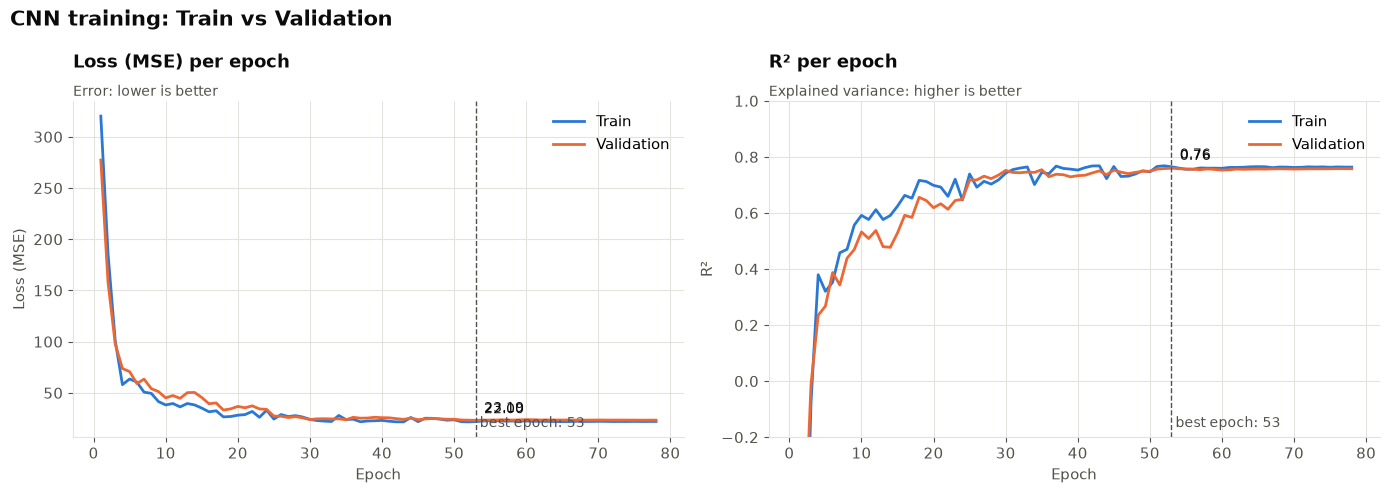

In [45]:
# -----------------------------------------------------------------------------
# Chart style (same for all the charts of this section)
# -----------------------------------------------------------------------------
# Fixed colors per set: Train = blue, Validation = orange, Test = green (colorblind-safe).
# Text in neutral gray tones; light grid; no top/right borders.
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

COLORS = {"Train": "#2a78d6", "Validation": "#eb6834", "Test": "#1baf7a"}
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "legend.frameon": False,
})

FIG_DIR = Path(r"..\output\CNN")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def set_title(ax, title, subtitle=None):
    """Bold title on the left + gray subtitle below it (with space, no overlap)."""
    ax.set_title(title, loc="left", pad=24 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.015, subtitle, transform=ax.transAxes, color=INK_2, fontsize=10)

# -----------------------------------------------------------------------------
# Learning curves: loss and R² per epoch, Train vs Validation
# -----------------------------------------------------------------------------
# Both curves come from EpochMetrics (Section IV): Train and Validation measured the same
# way at the end of each epoch (no Dropout, no rotation), so they can be compared.
hist   = pd.DataFrame(epoch_metrics.rows)
epochs = hist["epoch"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
panels = [("mse",  "Loss (MSE)", "Error: lower is better"),
          ("r2",   "R²",         "Explained variance: higher is better")]

for ax, (key, ylabel, subtitle) in zip(axes, panels):
    for name, col in [("Train", f"Train_{key}"), ("Validation", f"Validation_{key}")]:
        ax.plot(epochs, hist[col], color=COLORS[name], linewidth=2, label=name)
        # Direct label with the value at the best epoch
        ax.annotate(f"{hist[col].iloc[BEST_EPOCH - 1]:.2f}",
                    (BEST_EPOCH, hist[col].iloc[BEST_EPOCH - 1]),
                    xytext=(6, 6), textcoords="offset points", color=INK, fontsize=10)
    ax.axvline(BEST_EPOCH, color=INK_2, linestyle="--", linewidth=1)
    ax.text(BEST_EPOCH, 0.02, f" best epoch: {BEST_EPOCH}", transform=ax.get_xaxis_transform(),
            color=INK_2, va="bottom", fontsize=10)
    set_title(ax, f"{ylabel} per epoch", subtitle)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(loc="best")

axes[1].set_ylim(max(-0.2, hist[["Train_r2", "Validation_r2"]].min().min()), 1)   # R² readable range
fig.suptitle("CNN training: Train vs Validation", x=0.01, ha="left",
             fontsize=15, fontweight="bold", color=INK)
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

,Grids,Districts,R²,R² weighted (n_blocks),RMSE (pp),MAE (pp)
Set,,,,,,
Train,731,96,0.793,0.833,4.404,3.213
Validation,103,12,0.758,0.887,4.830,3.304
Test,110,13,0.680,0.722,4.803,3.692


Gap R² Train - Validation: 0.034 (small: the model generalizes)


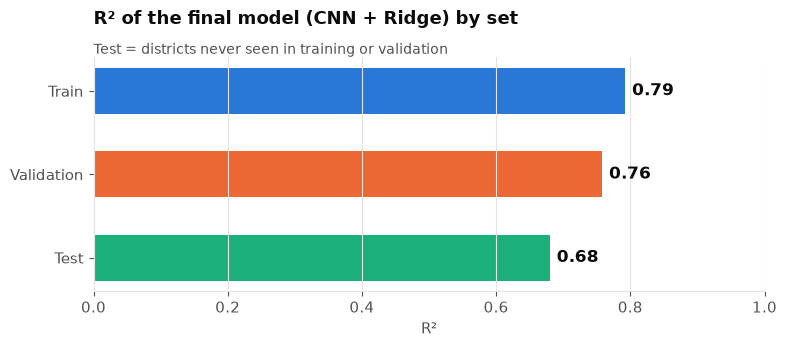

In [46]:
# -----------------------------------------------------------------------------
# Performance table: Train / Validation / Test
# -----------------------------------------------------------------------------
# Predictions with the final model (weights of the best epoch), WITHOUT Dropout and WITHOUT
# rotation: this is the real performance on each set.
# - R²   : share of the variance of Pobreza2018 explained by the model (1 = perfect).
# - RMSE : typical error in percentage points (penalizes large errors more).
# - MAE  : mean absolute error in percentage points.
# - R² weighted by n_blocks: grids with more blocks have a more reliable poverty rate
#   (average of more blocks); this R² gives them more weight.
# FINAL MODEL = 0.5 x CNN + 0.5 x Ridge
#   - Ridge: linear regression with an L2 penalty, on the SAME socioeconomic vector (no image).
#     It is a separate model, NOT part of the CNN. Trained on train only.
#   - Why average: Ridge is stable and captures the linear part; the CNN adds what it sees
#     in the image. Averaging reduces the error of each one (cross-validation R²:
#     CNN 0.57, Ridge 0.63, average 0.64).
from sklearn.linear_model import RidgeCV

ridge = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(F_train, y_train)

def predict_cnn(X, F):
    return model.predict({"image": X, "features": F}, batch_size=128, verbose=0).ravel()

def predict(X, F):
    return 0.5 * predict_cnn(X, F) + 0.5 * ridge.predict(F)

pred = {"Train":      predict(X_train, F_train),
        "Validation": predict(X_val,   F_val),
        "Test":       predict(X_test,  F_test)}
true = {"Train": y_train, "Validation": y_val, "Test": y_test}
idx  = {"Train": idx_train, "Validation": idx_val, "Test": idx_test}

rows = []
for s in pred:
    w = labeled["n_blocks"].to_numpy()[idx[s]]
    rows.append({
        "Set": s,
        "Grids": len(true[s]),
        "Districts": labeled["UBIGEO"].iloc[idx[s]].nunique(),
        "R²": r2_score(true[s], pred[s]),
        "R² weighted (n_blocks)": r2_score(true[s], pred[s], sample_weight=w),
        "RMSE (pp)": np.sqrt(mean_squared_error(true[s], pred[s])),
        "MAE (pp)": mean_absolute_error(true[s], pred[s]),
    })
metrics = pd.DataFrame(rows).set_index("Set")
display(metrics.round(3))

# Gap Train - Validation: a large gap means the model memorizes instead of learning
gap = metrics.loc["Train", "R²"] - metrics.loc["Validation", "R²"]
print(f"Gap R² Train - Validation: {gap:.3f} "
      f"({'small: the model generalizes' if gap < 0.10 else 'large: signs of overfitting'})")

# Bar chart of R² per set
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.barh(metrics.index[::-1], metrics["R²"][::-1],
               color=[COLORS[s] for s in metrics.index[::-1]], height=0.55)
for b, v in zip(bars, metrics["R²"][::-1]):
    ax.text(v + 0.01, b.get_y() + b.get_height() / 2, f"{v:.2f}",
            va="center", color=INK, fontsize=12, fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xlabel("R²")
ax.grid(axis="y", visible=False)
set_title(ax, "R² of the final model (CNN + Ridge) by set", "Test = districts never seen in training or validation")
fig.tight_layout()
fig.savefig(FIG_DIR / "r2_by_set.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
# -----------------------------------------------------------------------------
# What each part contributes: final model vs CNN alone vs Ridge alone
# -----------------------------------------------------------------------------
# Final > Ridge alone  ->  the image adds information beyond the socioeconomic vector.
X_sets = {"Train": (X_train, F_train), "Validation": (X_val, F_val), "Test": (X_test, F_test)}
baseline = pd.DataFrame({
    "Final (CNN + Ridge)":    [r2_score(true[s], pred[s]) for s in pred],
    "CNN alone":              [r2_score(true[s], predict_cnn(*X_sets[s])) for s in pred],
    "Ridge alone (variables)": [r2_score(true[s], ridge.predict(X_sets[s][1])) for s in pred],
}, index=list(pred))
display(baseline.round(3))

,Final (CNN + Ridge),CNN alone,Ridge alone (variables)
Train,0.793,0.765,0.774
Validation,0.758,0.760,0.727
Test,0.680,0.648,0.673


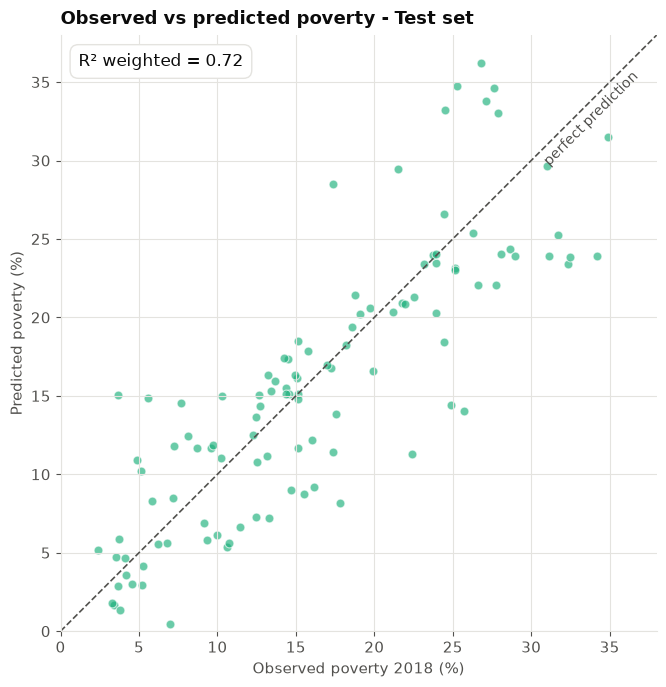

In [48]:
# -----------------------------------------------------------------------------
# Observed vs predicted poverty (TEST set only)
# -----------------------------------------------------------------------------
# X = observed Pobreza2018, Y = poverty predicted by the final model (CNN + Ridge). Each point is a 2 km grid
# of a district never seen by the model. The dashed 45° line is the perfect prediction:
# points above = model overestimates, below = model underestimates.
# Box: R² weighted by n_blocks (grids with more blocks have a more reliable observed rate).
y_t, p_t = y_test, pred["Test"]
w_t      = labeled["n_blocks"].to_numpy()[idx_test]

lim = (0, max(y_t.max(), p_t.max()) * 1.05)
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.scatter(y_t, p_t, s=40, color=COLORS["Test"], alpha=0.65,
           edgecolor="white", linewidth=0.8)
ax.plot(lim, lim, color=INK_2, linestyle="--", linewidth=1.2)
ax.text(lim[1] * 0.97, lim[1] * 0.93, "perfect prediction", color=INK_2,
        ha="right", fontsize=10, rotation=45, rotation_mode="anchor")

r2_t   = r2_score(y_t, p_t)
rmse_t = np.sqrt(mean_squared_error(y_t, p_t))
r2w_t  = r2_score(y_t, p_t, sample_weight=w_t)
ax.text(0.03, 0.97, f"R² weighted = {r2w_t:.2f}",
        transform=ax.transAxes, va="top", color=INK, fontsize=12,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor=GRID))

ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
ax.set_xlabel("Observed poverty 2018 (%)")
ax.set_ylabel("Predicted poverty (%)")
set_title(ax, "Observed vs predicted poverty - Test set")
fig.tight_layout()
fig.savefig(FIG_DIR / "observed_vs_predicted_test.png", dpi=150, bbox_inches="tight")
plt.show()

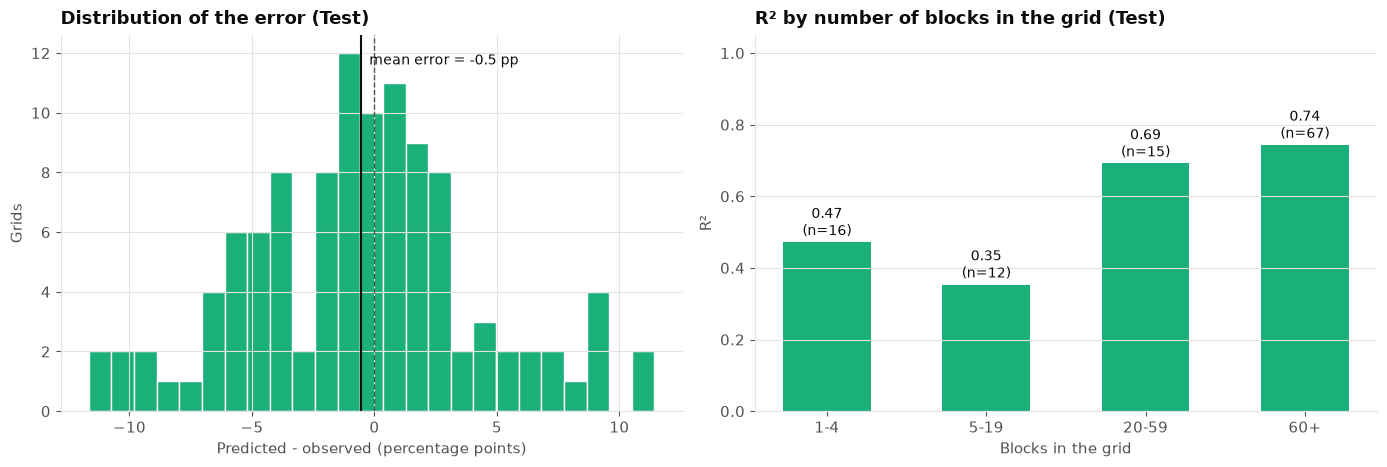

FINAL R² ON TEST SET: 0.680   (RMSE 4.80 pp | MAE 3.69 pp)
R² weighted by n_blocks on TEST: 0.722


In [49]:
# -----------------------------------------------------------------------------
# Errors on TEST: distribution and where the model fails
# -----------------------------------------------------------------------------
# Left : histogram of the errors (predicted - observed). Centered at 0 = no bias.
# Right: R² by reliability of the observed rate (grids grouped by number of blocks).
#        Grids with few blocks have a noisy observed rate: no model can predict noise.
resid = p_t - y_t
n_blk = labeled["n_blocks"].to_numpy()[idx_test]
bins  = pd.cut(n_blk, [0, 5, 20, 60, np.inf], right=False,
               labels=["1-4", "5-19", "20-59", "60+"])
by_rel = (pd.DataFrame({"bin": bins, "y": y_t, "p": p_t})
          .groupby("bin", observed=True)
          .apply(lambda g: pd.Series({"Grids": len(g),
                                      "R²": r2_score(g.y, g.p) if len(g) > 2 else np.nan})))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

ax = axes[0]
ax.hist(resid, bins=25, color=COLORS["Test"], edgecolor="white")
ax.axvline(0, color=INK_2, linestyle="--", linewidth=1)
ax.axvline(resid.mean(), color=INK, linewidth=1.5)
ax.text(resid.mean(), ax.get_ylim()[1] * 0.95, f"  mean error = {resid.mean():+.1f} pp",
        color=INK, fontsize=10, va="top")
set_title(ax, "Distribution of the error (Test)")
ax.set_xlabel("Predicted - observed (percentage points)")
ax.set_ylabel("Grids")

ax = axes[1]
b = ax.bar(by_rel.index.astype(str), by_rel["R²"], color=COLORS["Test"], width=0.55)
for rect, (r2v, n) in zip(b, by_rel[["R²", "Grids"]].to_numpy()):
    ax.text(rect.get_x() + rect.get_width() / 2, max(r2v, 0) + 0.02,
            f"{r2v:.2f}\n(n={int(n)})", ha="center", color=INK, fontsize=10)
ax.set_ylim(min(0, by_rel["R²"].min() - 0.1), 1.05)
ax.grid(axis="x", visible=False)
set_title(ax, "R² by number of blocks in the grid (Test)")
ax.set_xlabel("Blocks in the grid")
ax.set_ylabel("R²")

fig.tight_layout()
fig.savefig(FIG_DIR / "test_errors.png", dpi=150, bbox_inches="tight")
plt.show()

# ---- Final result on the test set ----
print("=" * 60)
print(f"FINAL R² ON TEST SET: {r2_t:.3f}   (RMSE {rmse_t:.2f} pp | "
      f"MAE {mean_absolute_error(y_t, p_t):.2f} pp)")
print(f"R² weighted by n_blocks on TEST: {metrics.loc['Test', 'R² weighted (n_blocks)']:.3f}")
print("=" * 60)

# VII. Predicción de pobreza en grids sin datos (Pobreza2018 missing)

Grids predicted: 3,350 | set to 0 (negative): 13 | set to 100 (> 100): 0


count    3350.00
mean       24.26
std         9.39
min         0.00
25%        16.86
50%        24.04
75%        32.27
max        46.75
Name: Pobreza2018_pred, dtype: float64

Saved to: ..\output\CNN


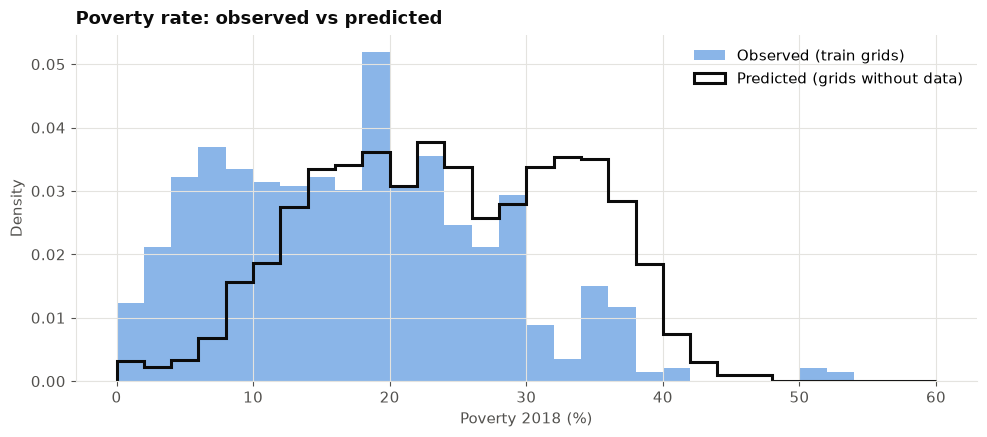

In [50]:
# -----------------------------------------------------------------------------
# Prediction of Pobreza2018 for the 2 km grids WITHOUT poverty data
# -----------------------------------------------------------------------------
# Uses nodata_ds (images + socioeconomic vector of `unlabeled`, scaled with TRAIN stats).
# A rate is between 0 and 100: negative predictions -> 0, predictions above 100 -> 100.
# The number of truncated values is reported (if it is large, the model extrapolates).
pred_nodata_raw = predict(X_nodata, F_nodata)            # final model (CNN + Ridge)
n_low, n_high   = int((pred_nodata_raw < 0).sum()), int((pred_nodata_raw > 100).sum())

predictions = unlabeled[["ID", "UBIGEO", "longitude", "latitude", "n_blocks",
                         "geometry"]].copy()
predictions["Pobreza2018_pred"] = np.clip(pred_nodata_raw, 0, 100)

print(f"Grids predicted: {len(predictions):,} | set to 0 (negative): {n_low} | "
      f"set to 100 (> 100): {n_high}")
display(predictions["Pobreza2018_pred"].describe().round(2))

# Save: table (CSV) and map layer (GeoPackage, keeps the geometry of the grids)
predictions.drop(columns="geometry").to_csv(FIG_DIR / "predictions_grid2km_cnn.csv", index=False)
gpd.GeoDataFrame(predictions, geometry="geometry", crs=grid2km_data.crs).to_file(
    FIG_DIR / "predictions_grid2km_cnn.gpkg", driver="GPKG")
print(f"Saved to: {FIG_DIR}")

# Distribution of the predictions vs the observed rates (train): similar shapes mean the
# model does not produce predictions outside the range it learned
fig, ax = plt.subplots(figsize=(10, 4.5))
binsh = np.linspace(0, max(60, predictions["Pobreza2018_pred"].max()), 31)
ax.hist(y_train, bins=binsh, density=True, color=COLORS["Train"], alpha=0.55,
        label="Observed (train grids)")
ax.hist(predictions["Pobreza2018_pred"], bins=binsh, density=True, histtype="step",
        linewidth=2.2, color=INK, label="Predicted (grids without data)")
set_title(ax, "Poverty rate: observed vs predicted")
ax.set_xlabel("Poverty 2018 (%)")
ax.set_ylabel("Density")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "prediction_distribution.png", dpi=150, bbox_inches="tight")
plt.show()